# 06_model_interpretation

## Ziel
In diesem Notebook wird das Kreditausfallmodell aus `05_default_risk_model.ipynb` interpretiert.

## Fragen
- Welche Variablen treiben das Ausfallrisiko?
- Wie wirken `old_score` und `new_score`?
- Welche Rolle spielen Einkommen, Liquidität und negative Einträge?
- Was passiert bei einer Person mit hohem Einkommen, aber schlechtem Score?

## Hinweis
Dieses Notebook ist bewusst kompakt aufgebaut, damit alle Schritte in Google Colab stabil nacheinander laufen.

In [11]:
import warnings
warnings.filterwarnings("ignore")

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
np.random.seed(42)

In [12]:
# Datei hochladen
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# CSV robust laden
try:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=",")
except:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep=";")

print("Datei geladen:", file_name)
print("Shape:", df.shape)
print("\nSpalten:")
print(df.columns.tolist())

df.head()

Saving synthetic_schufa_dataset.csv to synthetic_schufa_dataset (1).csv
Datei geladen: synthetic_schufa_dataset (1).csv
Shape: (10000, 21)

Spalten:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,...,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,...,9.2,0,0,4301.25,5.03,100.0,100.0,1,1,0
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,...,9.6,0,0,3233.97,2.04,100.0,100.0,0,1,0
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,...,10.8,0,0,-409.95,-0.16,93.8,100.0,1,1,1
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,...,5.6,0,0,-1898.47,-1.78,98.6,100.0,1,1,0
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,...,8.6,0,0,1761.98,1.31,96.7,99.4,1,1,0


In [13]:
# =========================================================
# DATENVORBEREITUNG KOMPLETT IN EINER ZELLE
# =========================================================

target = "default"

features = [
    "age",
    "net_income",
    "employment_status",
    "marital_status",
    "dependents",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score"
]

# Sicherheitscheck
missing_features = [col for col in features + [target] if col not in df.columns]
if missing_features:
    raise ValueError(f"Diese Spalten fehlen im Datensatz: {missing_features}")

# Modell-Datensatz
df_model = df[features + [target]].copy().dropna()

# Zielvariable und Features
X = df_model.drop(columns=[target])
y = df_model[target]

# Numerisch / kategorial erkennen
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# One-Hot-Encoding
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

# Train/Test-Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scaling nur für Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datenvorbereitung abgeschlossen.")
print("df_model:", df_model.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDefault-Verteilung:")
print(y.value_counts())
print("\nDefault in %:")
print((y.value_counts(normalize=True) * 100).round(2))

Datenvorbereitung abgeschlossen.
df_model: (10000, 19)
X_train: (8000, 21)
X_test: (2000, 21)

Default-Verteilung:
default
0    8699
1    1301
Name: count, dtype: int64

Default in %:
default
0    86.99
1    13.01
Name: proportion, dtype: float64


In [14]:
# =========================================================
# MODELLE TRAINIEREN + EVALUIEREN
# =========================================================

# Logistic Regression
log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)
log_model.fit(X_train_scaled, y_train)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
rf_model.fit(X_train, y_train)

# Vorhersagen
y_pred_log = log_model.predict(X_test_scaled)
y_proba_log = log_model.predict_proba(X_test_scaled)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Vergleich
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_log),
        roc_auc_score(y_test, y_proba_rf)
    ]
}).sort_values("ROC-AUC", ascending=False)

print("Modellvergleich:")
display(comparison)

print("\nClassification Report - Logistic Regression")
print(classification_report(y_test, y_pred_log))

print("\nClassification Report - Random Forest")
print(classification_report(y_test, y_pred_rf))

Modellvergleich:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Random Forest,0.747,0.245868,0.457692,0.319892,0.705533
0,Logistic Regression,0.659,0.206128,0.569231,0.302658,0.674783



Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.91      0.67      0.77      1740
           1       0.21      0.57      0.30       260

    accuracy                           0.66      2000
   macro avg       0.56      0.62      0.54      2000
weighted avg       0.82      0.66      0.71      2000


Classification Report - Random Forest
              precision    recall  f1-score   support

           0       0.91      0.79      0.84      1740
           1       0.25      0.46      0.32       260

    accuracy                           0.75      2000
   macro avg       0.58      0.62      0.58      2000
weighted avg       0.82      0.75      0.78      2000



Top positive Koeffizienten:


,feature,coefficient
6,debt_to_income,0.391604
7,late_payments,0.238111
10,negative_entry,0.214811
11,collection_cases,0.196548
13,liquidity_ratio,0.183452
5,credit_amount,0.067122
9,credit_history_years,0.066783
2,dependents,0.066548
4,existing_loans,0.066290
0,age,0.039933


Top negative Koeffizienten:


,feature,coefficient
16,employment_status_arbeitslos,0.013294
19,marital_status_ledig,0.011227
20,marital_status_verheiratet,0.002609
18,employment_status_teilzeit,-0.005098
8,hard_inquiries,-0.041046
17,employment_status_selbstständig,-0.096153
14,old_score,-0.107118
3,monthly_expenses,-0.130359
1,net_income,-0.170047
12,bank_balance,-0.377909


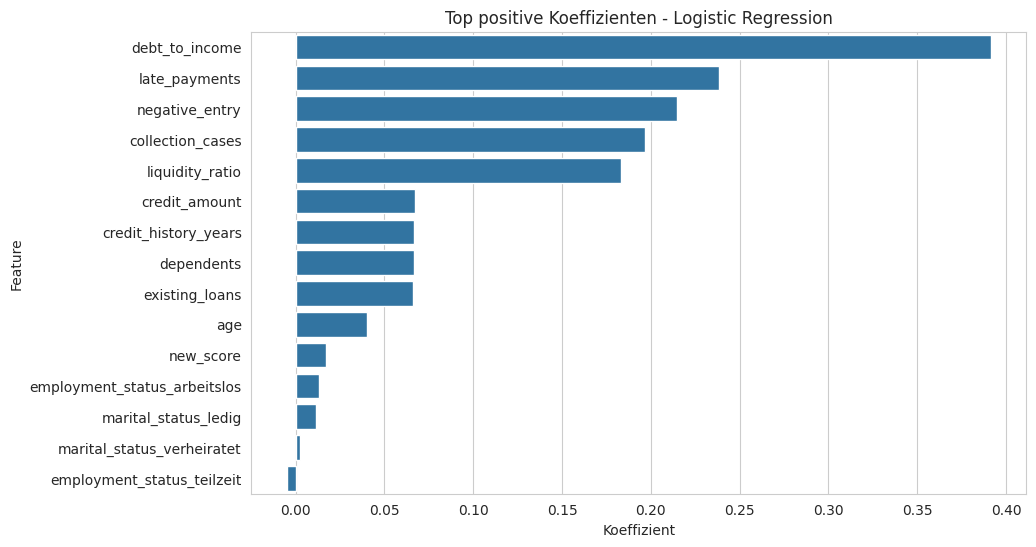

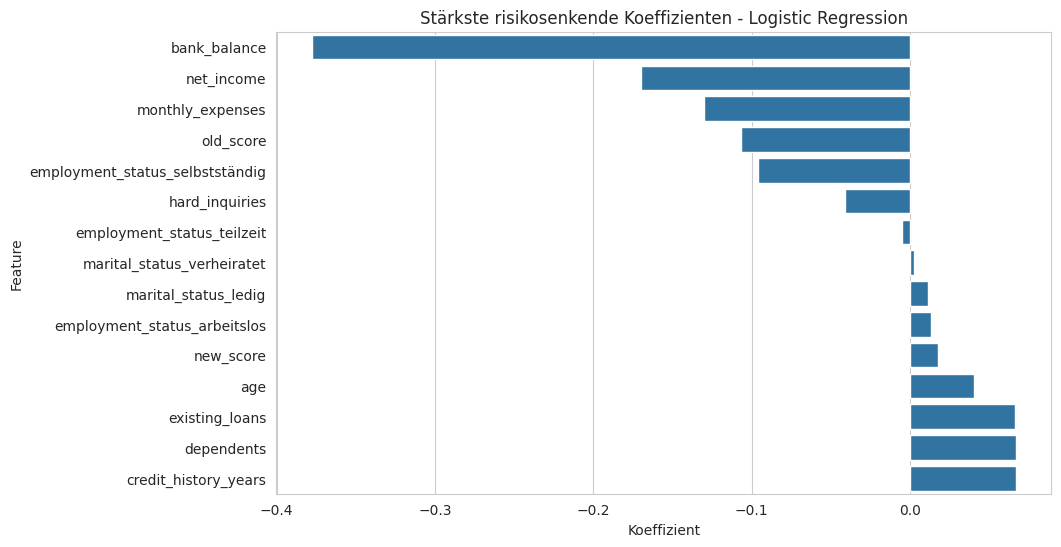

Top Feature Importances:


,feature,importance
6,debt_to_income,0.178939
14,old_score,0.099403
1,net_income,0.097416
3,monthly_expenses,0.083968
5,credit_amount,0.081373
12,bank_balance,0.077975
13,liquidity_ratio,0.060599
15,new_score,0.050988
9,credit_history_years,0.050135
0,age,0.046992


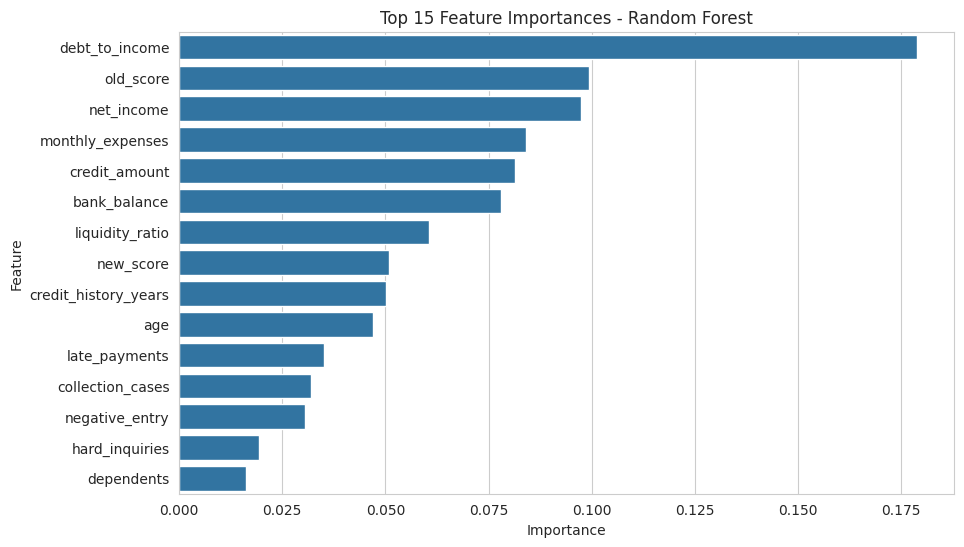

Top Permutation Importances:


,feature,importance_mean,importance_std
6,debt_to_income,0.074900,0.008394
14,old_score,0.031191,0.003881
1,net_income,0.022548,0.006142
3,monthly_expenses,0.012818,0.004906
11,collection_cases,0.010021,0.001673
10,negative_entry,0.006141,0.002092
12,bank_balance,0.004016,0.006050
7,late_payments,0.003816,0.002491
0,age,0.003314,0.002344
9,credit_history_years,0.001545,0.001877


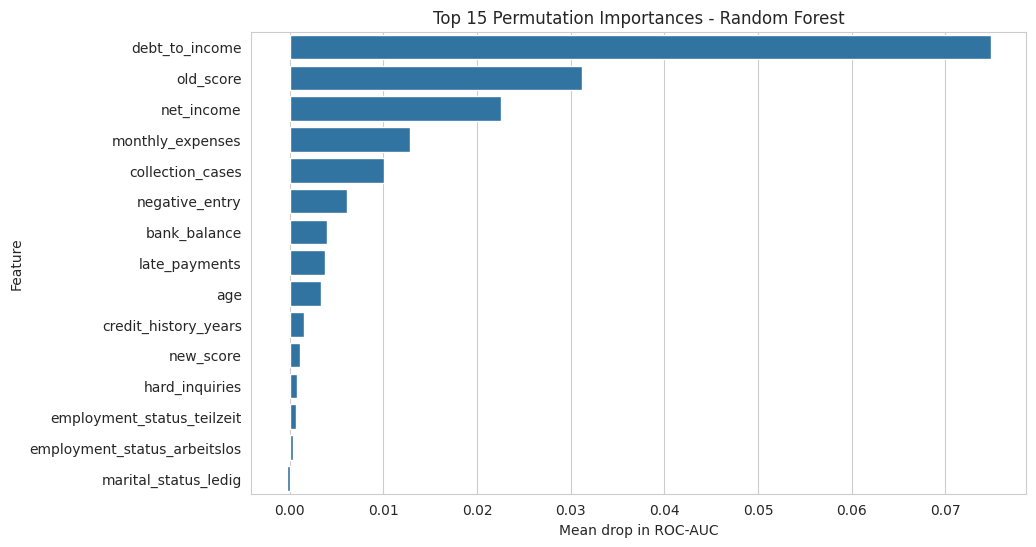

Vergleich old_score vs new_score - Feature Importance


,feature,importance
14,old_score,0.099403
15,new_score,0.050988


Vergleich old_score vs new_score - Logistic Coefficients


,feature,coefficient
15,new_score,0.017301
14,old_score,-0.107118


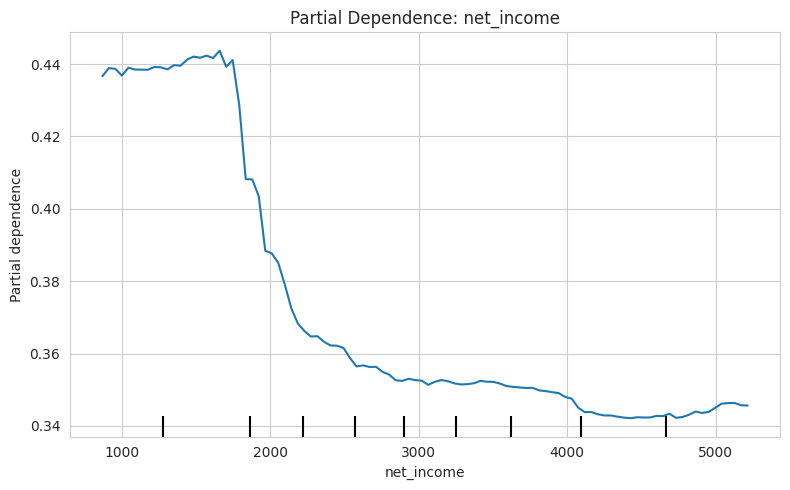

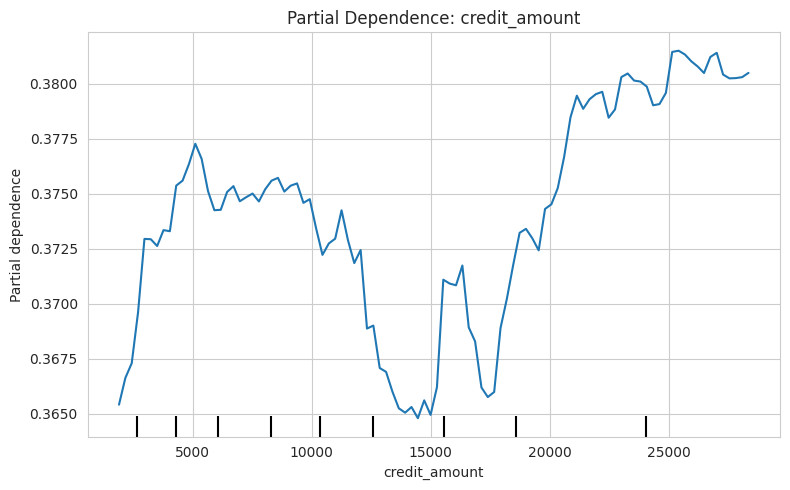

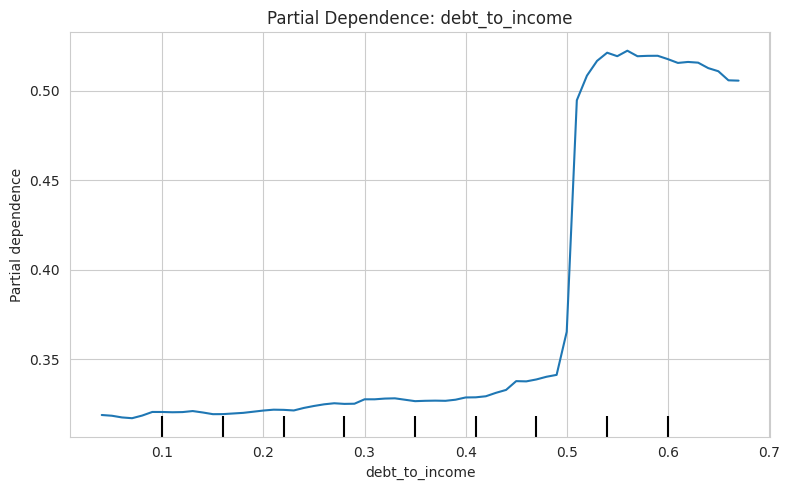

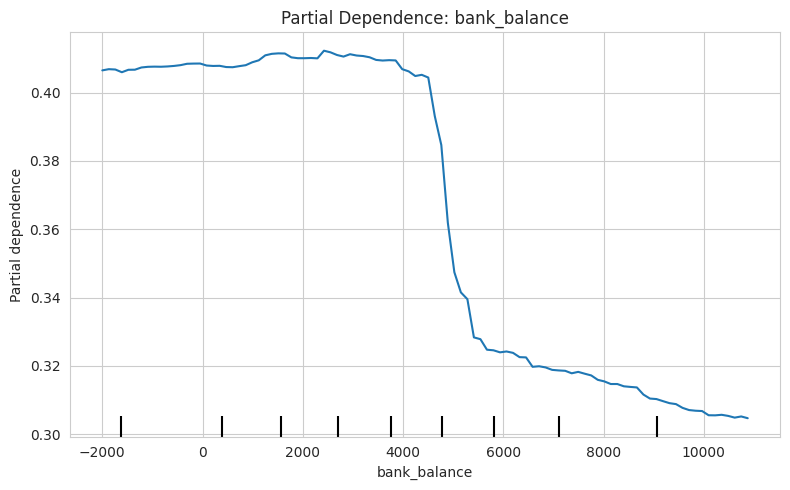

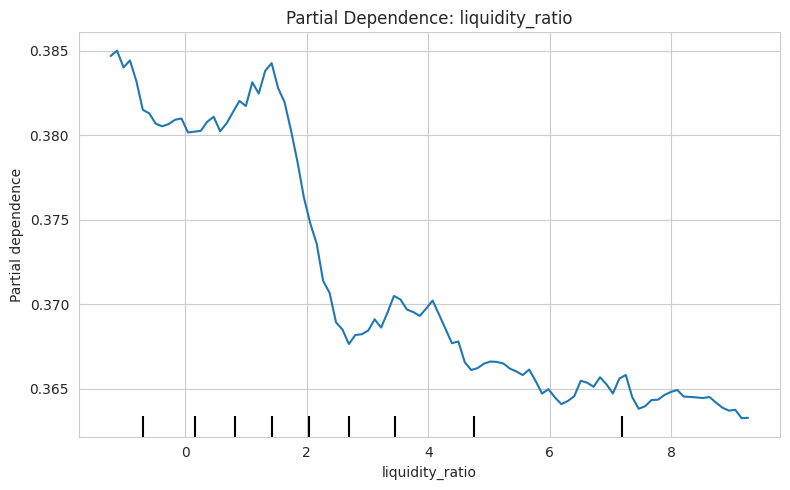

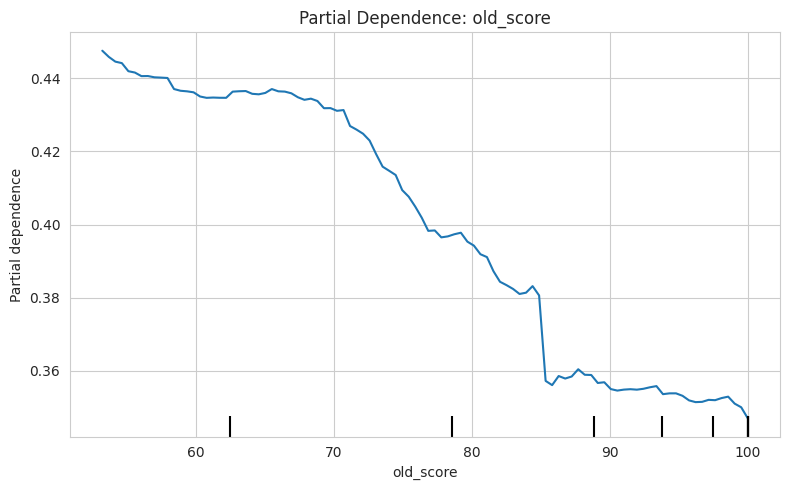

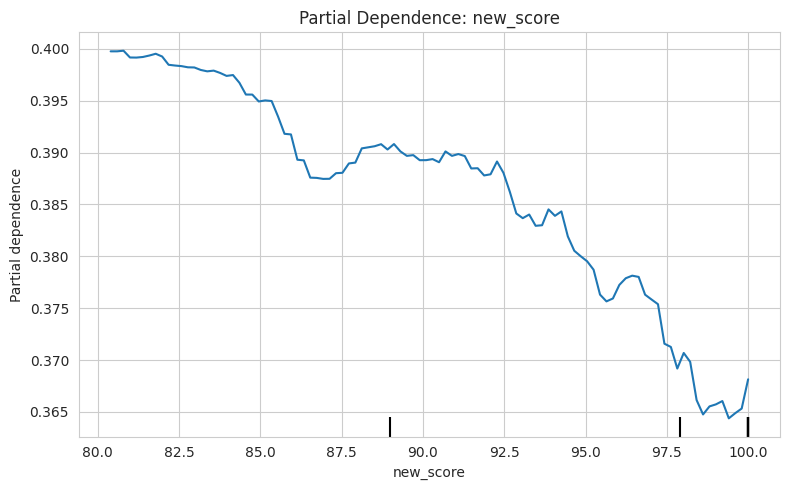

In [15]:
# =========================================================
# MODELLINTERPRETATION
# =========================================================

# -----------------------------
# 1. Logistic Regression Koeffizienten
# -----------------------------
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": log_model.coef_[0]
}).sort_values("coefficient", ascending=False)

print("Top positive Koeffizienten:")
display(coef_df.head(10))

print("Top negative Koeffizienten:")
display(coef_df.tail(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df.head(15), x="coefficient", y="feature")
plt.title("Top positive Koeffizienten - Logistic Regression")
plt.xlabel("Koeffizient")
plt.ylabel("Feature")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=coef_df.tail(15).sort_values("coefficient", ascending=True),
    x="coefficient",
    y="feature"
)
plt.title("Stärkste risikosenkende Koeffizienten - Logistic Regression")
plt.xlabel("Koeffizient")
plt.ylabel("Feature")
plt.show()

# -----------------------------
# 2. Random Forest Feature Importance
# -----------------------------
feature_importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top Feature Importances:")
display(feature_importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(15), x="importance", y="feature")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# -----------------------------
# 3. Permutation Importance
# -----------------------------
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

print("Top Permutation Importances:")
display(perm_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=perm_df.head(15), x="importance_mean", y="feature")
plt.title("Top 15 Permutation Importances - Random Forest")
plt.xlabel("Mean drop in ROC-AUC")
plt.ylabel("Feature")
plt.show()

# -----------------------------
# 4. Old Score vs New Score
# -----------------------------
score_compare_importance = feature_importance_df[
    feature_importance_df["feature"].isin(["old_score", "new_score"])
].copy()

score_compare_coef = coef_df[
    coef_df["feature"].isin(["old_score", "new_score"])
].copy()

print("Vergleich old_score vs new_score - Feature Importance")
display(score_compare_importance)

print("Vergleich old_score vs new_score - Logistic Coefficients")
display(score_compare_coef)

# -----------------------------
# 5. Partial Dependence Plots
# -----------------------------
pdp_candidates = [
    col for col in [
        "net_income",
        "credit_amount",
        "debt_to_income",
        "bank_balance",
        "liquidity_ratio",
        "old_score",
        "new_score"
    ] if col in X_test.columns
]

for feature in pdp_candidates:
    fig, ax = plt.subplots(figsize=(8, 5))
    PartialDependenceDisplay.from_estimator(rf_model, X_test, [feature], ax=ax)
    plt.title(f"Partial Dependence: {feature}")
    plt.tight_layout()
    plt.show()

Fallbeispiel:


,2906
age,60
net_income,4000
dependents,0
monthly_expenses,1130.62
existing_loans,0
credit_amount,12000
debt_to_income,0.25
late_payments,1
hard_inquiries,2
credit_history_years,11.0


Vorhersage für Fallbeispiel:


,Model,Predicted Default Probability
0,Logistic Regression,0.459465
1,Random Forest,0.462058


Top risikosteigernde Beiträge:


,feature,value,coefficient,standardized_value,linear_contribution
10,negative_entry,1,0.214811,1.899551,0.408044
14,old_score,35,-0.107118,-3.460244,0.370655
3,monthly_expenses,1130.62,-0.130359,-0.813171,0.106004
17,employment_status_selbstständig,False,-0.096153,-0.461363,0.044362
0,age,60,0.039933,1.096356,0.043781
9,credit_history_years,11.0,0.066783,0.611236,0.040820
19,marital_status_ledig,True,0.011227,1.106939,0.012427
18,employment_status_teilzeit,False,-0.005098,-0.451166,0.002300
5,credit_amount,12000,0.067122,0.007245,0.000486
8,hard_inquiries,2,-0.041046,0.001866,-0.000077


Top risikosenkende Beiträge:


,feature,value,coefficient,standardized_value,linear_contribution
16,employment_status_arbeitslos,False,0.013294,-0.294633,-0.003917
7,late_payments,1,0.238111,-0.022373,-0.005327
13,liquidity_ratio,2.2,0.183452,-0.154165,-0.028282
2,dependents,0,0.066548,-0.882277,-0.058714
4,existing_loans,0,0.066290,-1.099098,-0.072859
11,collection_cases,0,0.196548,-0.406854,-0.079966
15,new_score,55,0.017301,-5.856133,-0.101315
1,net_income,4000,-0.170047,0.905886,-0.154043
6,debt_to_income,0.25,0.391604,-0.579078,-0.226769
12,bank_balance,6500,-0.377909,0.666511,-0.251881


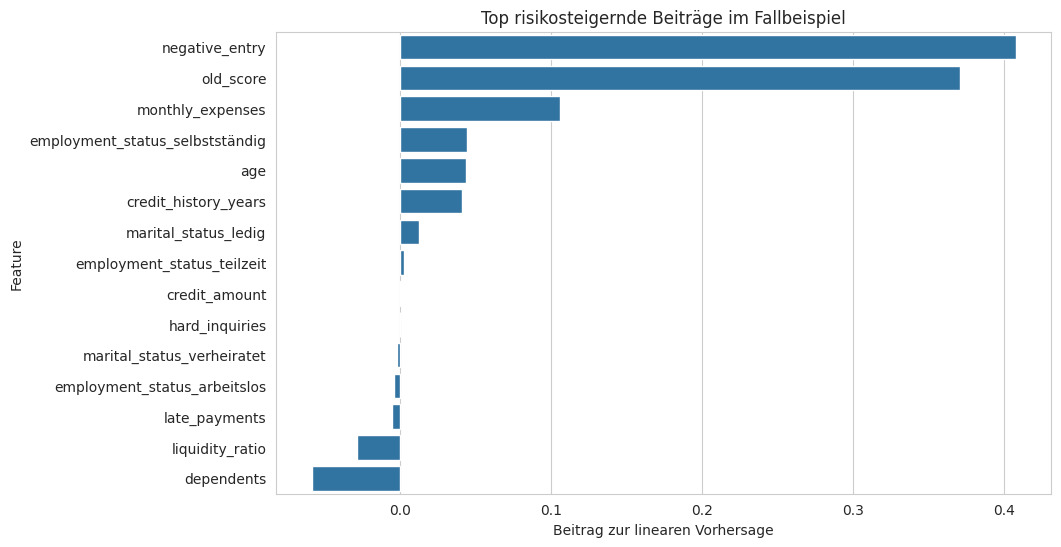

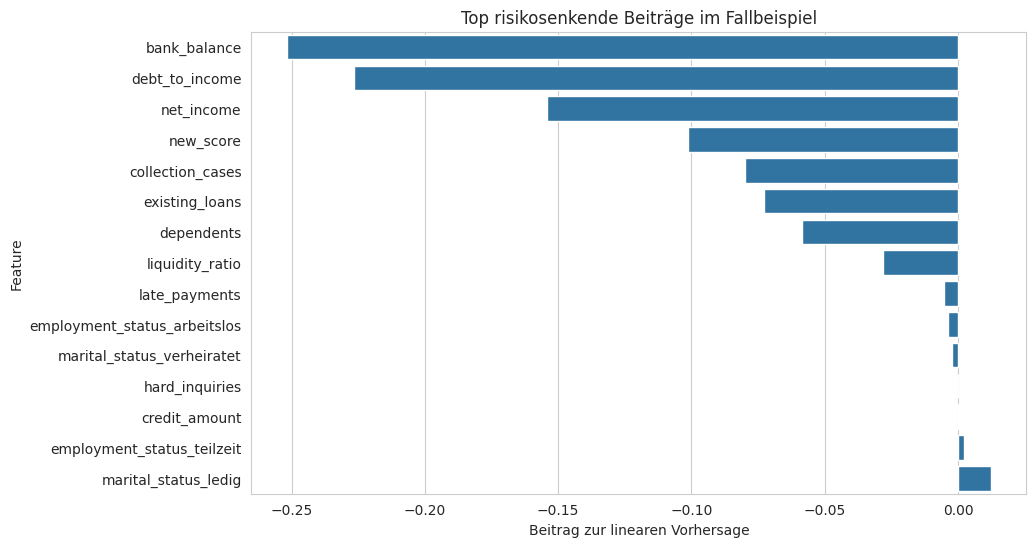

Gruppenvergleich nach negative_entry:


pred_rf_prob                 pred_log_prob                
                       mean    median count          mean    median count
negative_entry                                                           
0                  0.341704  0.323401  1572      0.400250  0.396052  1572
1                  0.496867  0.505059   428      0.620105  0.633910   428

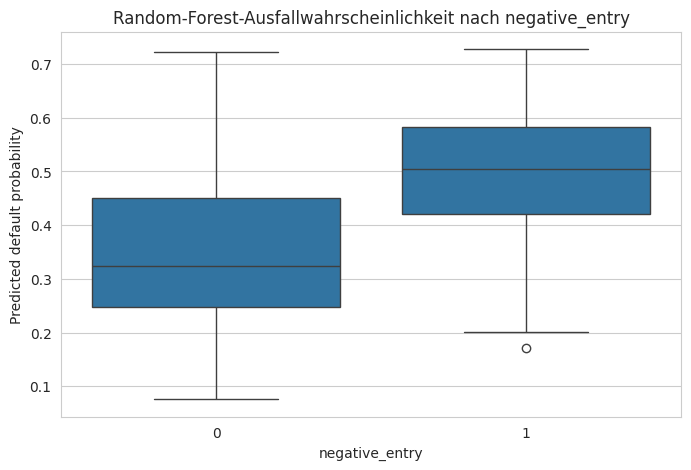

Durchschnittliche RF-Ausfallwahrscheinlichkeit nach Einkommen und negative_entry:


negative_entry,0,1
income_group,,
niedrig,0.437398,0.559726
mittel,0.324319,0.524217
hoch,0.305385,0.490074
sehr hoch,0.293924,0.447335


In [16]:
# =========================================================
# FALLANALYSE: HOHES EINKOMMEN, ABER SCHLECHTER SCORE
# =========================================================

# Ausgangspunkt: ein echter Testfall
case = X_test.iloc[[0]].copy()

# Fall gezielt anpassen
for col in case.columns:
    if col == "net_income":
        case[col] = 4000
    elif col == "credit_amount":
        case[col] = 12000
    elif col == "debt_to_income":
        case[col] = 0.25
    elif col == "bank_balance":
        case[col] = 6500
    elif col == "liquidity_ratio":
        case[col] = 2.2
    elif col == "old_score":
        case[col] = 35
    elif col == "new_score":
        case[col] = 55
    elif col == "negative_entry":
        case[col] = 1
    elif col == "collection_cases":
        case[col] = 0
    elif col == "late_payments":
        case[col] = 1

print("Fallbeispiel:")
display(case.T)

# Vorhersage
case_scaled = scaler.transform(case)

case_log_prob = log_model.predict_proba(case_scaled)[:, 1][0]
case_rf_prob = rf_model.predict_proba(case)[:, 1][0]

case_result = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Predicted Default Probability": [case_log_prob, case_rf_prob]
})

print("Vorhersage für Fallbeispiel:")
display(case_result)

# Lokale Beitragsanalyse für Logistic Regression
case_contrib = pd.DataFrame({
    "feature": X_train.columns,
    "value": case.iloc[0].values,
    "coefficient": log_model.coef_[0],
    "standardized_value": case_scaled[0]
})

case_contrib["linear_contribution"] = (
    case_contrib["coefficient"] * case_contrib["standardized_value"]
)

case_contrib = case_contrib.sort_values("linear_contribution", ascending=False)

print("Top risikosteigernde Beiträge:")
display(case_contrib.head(10))

print("Top risikosenkende Beiträge:")
display(case_contrib.tail(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=case_contrib.head(15), x="linear_contribution", y="feature")
plt.title("Top risikosteigernde Beiträge im Fallbeispiel")
plt.xlabel("Beitrag zur linearen Vorhersage")
plt.ylabel("Feature")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=case_contrib.tail(15).sort_values("linear_contribution", ascending=True),
    x="linear_contribution",
    y="feature"
)
plt.title("Top risikosenkende Beiträge im Fallbeispiel")
plt.xlabel("Beitrag zur linearen Vorhersage")
plt.ylabel("Feature")
plt.show()

# Gruppenvergleich
analysis_df = X_test.copy()
analysis_df["actual_default"] = y_test.values
analysis_df["pred_rf_prob"] = y_proba_rf
analysis_df["pred_log_prob"] = y_proba_log

if "negative_entry" in analysis_df.columns:
    print("Gruppenvergleich nach negative_entry:")
    group_negative = analysis_df.groupby("negative_entry")[["pred_rf_prob", "pred_log_prob"]].agg(["mean", "median", "count"])
    display(group_negative)

    plt.figure(figsize=(8, 5))
    sns.boxplot(x=analysis_df["negative_entry"], y=analysis_df["pred_rf_prob"])
    plt.title("Random-Forest-Ausfallwahrscheinlichkeit nach negative_entry")
    plt.xlabel("negative_entry")
    plt.ylabel("Predicted default probability")
    plt.show()

if "net_income" in analysis_df.columns:
    analysis_df["income_group"] = pd.qcut(
        analysis_df["net_income"],
        q=4,
        labels=["niedrig", "mittel", "hoch", "sehr hoch"]
    )

    if "negative_entry" in analysis_df.columns:
        pivot_income_negative = analysis_df.pivot_table(
            values="pred_rf_prob",
            index="income_group",
            columns="negative_entry",
            aggfunc="mean"
        )
        print("Durchschnittliche RF-Ausfallwahrscheinlichkeit nach Einkommen und negative_entry:")
        display(pivot_income_negative)

# Fazit

## Was dieses Notebook zeigt
Dieses Notebook erklärt nicht nur, **wie gut** das Modell vorhersagt, sondern auch, **warum** es so entscheidet.

## Zentrale Erkenntnisse
1. Die wichtigsten Risikotreiber liegen typischerweise im Zusammenspiel von:
   - Score
   - Zahlungsverhalten
   - Verschuldung
   - Kontostand
   - Liquidität

2. Wenn `new_score` wichtiger oder konsistenter ist als `old_score`, spricht das dafür, dass ein moderneres Scoring-System Risiken besser abbildet.

3. Die Fallanalyse zeigt, dass Personen mit hoher aktueller Zahlungsfähigkeit dennoch als riskant eingestuft werden können, wenn historische Negativmerkmale stark gewichtet werden.

4. Damit macht das Notebook den Zielkonflikt sichtbar:
   - historische Bonität
   - vs. aktuelle finanzielle Tragfähigkeit

## Bedeutung für dein Projekt
Das Projekt ist damit nicht nur ein Machine-Learning-Projekt, sondern auch eine wirtschaftliche Analyse von Kreditentscheidungen, Scoring-Systemen und möglicher Benachteiligung bestimmter Kundengruppen.